# Grafos sintéticos (ER, BA, WS) vs. rede real Facebook ego (SNAP)

**Versão 2.0 (corrigida).** A versão entregue ao professor está em `../original/` (tag `v1.0`). O que mudou e por quê está na seção *Errata* do README.

Este notebook tem duas partes:

1. **Parte 1:** famílias de grafos sintéticos (Erdős–Rényi, Barabási–Albert, Watts–Strogatz) com sementes fixas, e três perguntas de pesquisa (Q1, Q2, Q3).
2. **Parte 2:** a rede real *ego-Facebook* (SNAP) comparada com paralelos sintéticos de mesmo *n* e grau médio, robustez, estrutura de comunidades e distribuição de grau.

O dataset **não** está no repositório: é baixado do SNAP em tempo de execução (ver célula da Parte 2).

In [1]:
import os, gzip, urllib.request, warnings
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})

RESULTS = "../results"   # CSVs e figuras
DATA = "../data"         # dataset baixado (ignorado pelo git)
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(DATA, exist_ok=True)

print("NetworkX", nx.__version__, "| NumPy", np.__version__, "| pandas", pd.__version__)

NetworkX 3.7 | NumPy 2.5.5 | pandas 3.1.1


## Parte 1: funções de extração

**Correção do bug de sobrescrita.** Na versão 1.0, `extract_metrics` devolvia as chaves `"n"` e `"m"` (tamanho do maior componente conexo e número de arestas). Como `run_one` fazia `{"n": n, ..., **params, **extract_metrics(G)}`, essas chaves **sobrescreviam** o `n` nominal (em 9 dos 36 grafos ER, p=0,01 e p=0,05, o grafo não era conexo) e o parâmetro `m` do BA (em todos os 36 grafos BA). Agora as chaves são `n_lcc` e `m_arestas`, e `n`/`m` ficam sempre com os valores nominais.

Como todos os grafos da grade têm *n* ≤ 500, caminhos mínimos e diâmetro são **exatos** (todos os pares). Só a betweenness usa amostragem (`k = min(200, n_lcc)`, ou seja, exata para n=100). O ramo de amostragem de caminhos que existia na v1.0 nunca era executado nesta grade e foi removido.

Para o WS com β=0 (grafo regular) a variância do grau é zero e a assortatividade é indefinida: ela é registrada como `NaN` de forma explícita (a v1.0 registrava `NaN` com um `RuntimeWarning`).

In [2]:
def degree_assortativity(G, deg):
    """Assortatividade de grau; NaN explícito para grafos regulares (variância zero)."""
    if deg.var() == 0:
        return float("nan")
    return nx.degree_assortativity_coefficient(G)

def extract_metrics(G, bet_k=200):
    """Métricas do maior componente conexo (LCC) de G. Chaves n_lcc/m_arestas não colidem com n/m nominais."""
    if not nx.is_connected(G):
        G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    n_lcc, m_arestas = G.number_of_nodes(), G.number_of_edges()
    deg = np.array([d for _, d in G.degree()])

    lengths = []
    for _, dists in nx.all_pairs_shortest_path_length(G):   # exato (n <= 500)
        lengths.extend(v for v in dists.values() if v > 0)

    bet = nx.betweenness_centrality(G, k=min(bet_k, n_lcc), seed=0)
    return {
        "n_lcc": n_lcc, "m_arestas": m_arestas,
        "avg_degree": deg.mean(), "max_degree": int(deg.max()), "degree_var": deg.var(),
        "density": nx.density(G),
        "clustering_global": nx.transitivity(G),
        "clustering_avg": nx.average_clustering(G),
        "assortativity": degree_assortativity(G, deg),
        "diameter": nx.diameter(G),
        "avg_shortest_path": float(np.mean(lengths)),
        "max_betweenness": max(bet.values()),
        "max_closeness": max(nx.closeness_centrality(G).values()),
        "max_pagerank": max(nx.pagerank(G).values()),
    }

def run_one(model, n, seed, params):
    if model == "ER":
        G = nx.erdos_renyi_graph(n, params["p"], seed=seed)
    elif model == "BA":
        G = nx.barabasi_albert_graph(n, params["m"], seed=seed)
    elif model == "WS":
        G = nx.watts_strogatz_graph(n, params["k"], params["beta"], seed=seed)
    row = {"model": model, "n": n, "seed": seed, **params, **extract_metrics(G)}
    row["lcc_frac"] = row["n_lcc"] / n
    return row

## Parte 1: grade experimental

3 valores de *n* × 3 sementes × (4 ER + 4 BA + 15 WS) = **207 grafos**. Sementes fixas (0, 1, 2), ou seja, a execução é reprodutível.

In [3]:
N_VALUES = [100, 300, 500]
SEEDS    = [0, 1, 2]
ER_P     = [0.01, 0.05, 0.1, 0.2]
BA_M     = [1, 2, 5, 10]
WS_K     = [4, 6, 10]
WS_BETA  = [0.0, 0.01, 0.1, 0.5, 1.0]

tasks = []
for n in N_VALUES:
    for s in SEEDS:
        for p in ER_P:             tasks.append(("ER", n, s, {"p": p}))
        for m in BA_M:             tasks.append(("BA", n, s, {"m": m}))
        for k in WS_K:
            for b in WS_BETA:      tasks.append(("WS", n, s, {"k": k, "beta": b}))

print(f"Gerando {len(tasks)} grafos...")
results = []
for i, t in enumerate(tasks, 1):
    results.append(run_one(*t))
    if i % 50 == 0:
        print(f"  {i}/{len(tasks)}")
df = pd.DataFrame(results)
df.to_csv(f"{RESULTS}/metricas_sinteticas.csv", index=False)

# Verificação do bug corrigido: n e m nominais preservados
assert set(df["n"]) == set(N_VALUES)
assert set(df.loc[df.model == "BA", "m"]) == set(BA_M)
nao_conexos = df[df.lcc_frac < 1]
print("Shape:", df.shape)
print(f"Grafos com maior componente < n nominal: {len(nao_conexos)} de {len(df)} (modelos: {sorted(set(nao_conexos.model))})")
df.head()

Gerando 207 grafos...


  50/207


  100/207


  150/207


  200/207


Shape: (207, 22)
Grafos com maior componente < n nominal: 9 de 207 (modelos: ['ER'])


,model,n,seed,p,n_lcc,m_arestas,avg_degree,max_degree,degree_var,density,...,assortativity,diameter,avg_shortest_path,max_betweenness,max_closeness,max_pagerank,lcc_frac,m,k,beta
0,ER,100,0,0.01,20,20,2.000000,3,0.500000,0.105263,...,-0.142857,10,4.678947,0.643275,0.316667,0.079750,0.20,NaN,NaN,NaN
1,ER,100,0,0.05,99,280,5.656566,12,6.205285,0.057720,...,-0.001943,6,2.803958,0.071823,0.429825,0.020094,0.99,NaN,NaN,NaN
2,ER,100,0,0.10,100,511,10.220000,20,8.431600,0.103232,...,0.014546,4,2.206667,0.036067,0.526596,0.017834,1.00,NaN,NaN,NaN
3,ER,100,0,0.20,100,974,19.480000,30,14.089600,0.196768,...,-0.019380,3,1.818788,0.019530,0.589286,0.014466,1.00,NaN,NaN,NaN
4,BA,100,0,NaN,100,99,1.980000,18,5.799600,0.020000,...,-0.265817,9,4.816566,0.684395,0.336735,0.078962,1.00,1.0,NaN,NaN


## Parte 1: panorama das métricas

No painel "caminho médio vs n" o eixo x agora usa o **n nominal** (na v1.0 o ER aparecia com 15 valores de x por causa do bug). Para WS e BA a curva é uma média sobre todos os parâmetros do modelo, então o WS mistura β=0 (anel, L ∝ n) com β>0.

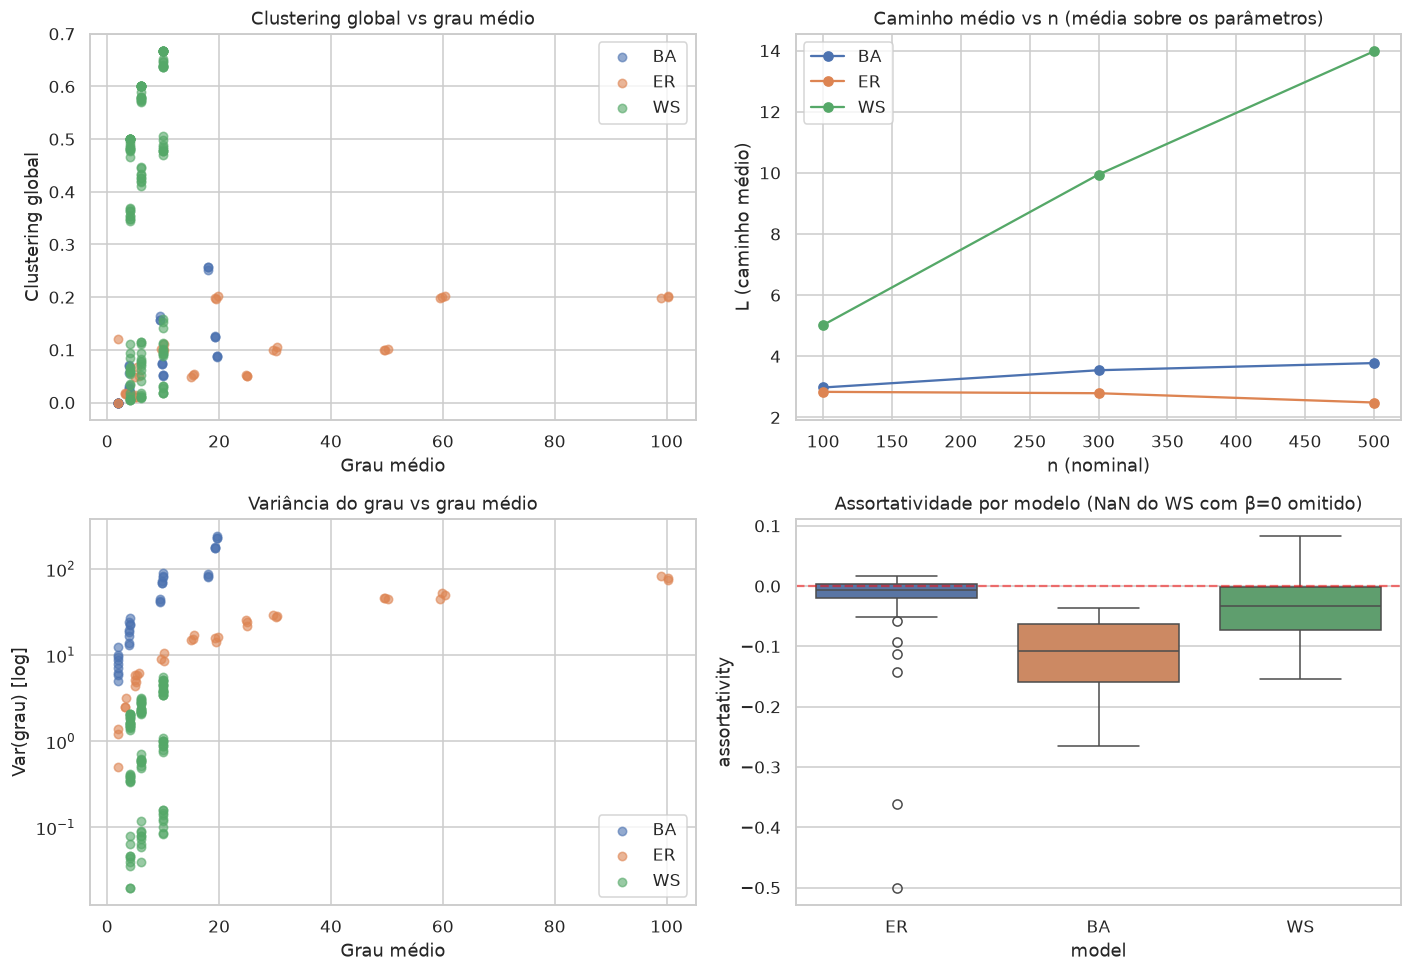

L médio por modelo e n nominal:
n        100    300     500
model                      
BA     2.978  3.542   3.776
ER     2.835  2.790   2.486
WS     5.021  9.944  13.975

WS com β=0 (anel regular), L por k e n:
n       100    300    500
k                        
4.0   12.88  37.88  62.88
6.0    8.76  25.42  42.08
10.0   5.45  15.45  25.45

Linhas com assortatividade NaN: 27 (modelos: ['WS'], β: [0.0])


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

ax = axes[0, 0]
for model, sub in df.groupby("model"):
    ax.scatter(sub["avg_degree"], sub["clustering_global"], label=model, alpha=0.6, s=30)
ax.set_xlabel("Grau médio"); ax.set_ylabel("Clustering global")
ax.set_title("Clustering global vs grau médio"); ax.legend()

ax = axes[0, 1]
for model, sub in df.groupby("model"):
    g = sub.groupby("n")["avg_shortest_path"].mean()
    ax.plot(g.index, g.values, "o-", label=model)
ax.set_xlabel("n (nominal)"); ax.set_ylabel("L (caminho médio)")
ax.set_title("Caminho médio vs n (média sobre os parâmetros)"); ax.legend()

ax = axes[1, 0]
for model, sub in df.groupby("model"):
    ax.scatter(sub["avg_degree"], sub["degree_var"], label=model, alpha=0.6, s=30)
ax.set_yscale("log")
ax.set_xlabel("Grau médio"); ax.set_ylabel("Var(grau) [log]")
ax.set_title("Variância do grau vs grau médio"); ax.legend()

ax = axes[1, 1]
sns.boxplot(data=df, x="model", y="assortativity", hue="model", legend=False, ax=ax)
ax.axhline(0, color="red", ls="--", alpha=0.5)
ax.set_title("Assortatividade por modelo (NaN do WS com β=0 omitido)")

plt.tight_layout(); plt.savefig(f"{RESULTS}/parte1_geral.png", dpi=130, bbox_inches="tight"); plt.show()

print("L médio por modelo e n nominal:")
print(df.groupby(["model", "n"])["avg_shortest_path"].mean().unstack().round(3))
print("\nWS com β=0 (anel regular), L por k e n:")
print(df[(df.model == "WS") & (df.beta == 0)].groupby(["k", "n"])["avg_shortest_path"].mean().unstack().round(2))
nan_rows = df[df.assortativity.isna()]
print(f"\nLinhas com assortatividade NaN: {len(nan_rows)} (modelos: {sorted(set(nan_rows.model))}, β: {sorted(set(nan_rows.beta))})")

**Leitura (Parte 1, panorama).**

- O L do **ER** *diminui* com n nesta grade (2,84 → 2,79 → 2,49), porque p é fixo e portanto o grau médio cresce com n. A v1.0 dizia que "os três modelos crescem aproximadamente como log(n)"; isso **não** se sustenta para o ER.
- O L do **BA** cresce com n (2,98 → 3,54 → 3,78).
- O L do **WS** com β=0 cresce linearmente com n (k=4: 12,9 → 37,9 → 62,9), como esperado para um anel; a média sobre β fica entre 5 e 14 e é dominada pelos β baixos.
- A variância do grau do BA é maior que a de ER e WS (eixo logarítmico), compatível com cauda pesada; o painel não permite quantificar "ordens de grandeza".

## Q1: em G(n, p), o clustering global acompanha p?

Teoria: em G(n, p) as arestas são independentes, logo a probabilidade de fechar um par de vizinhos é p, e C ≈ p.

Ressalva importante: as métricas são calculadas no **maior componente conexo**. Para p=0,01 (grau médio ≈ 1 a 5, regime sub ou próximo do crítico) o LCC é pequeno e atípico, então o C medido ali não representa G(n, p).

Clustering global médio por (p, n):
n        100     300     500
p                           
0.01  0.0400  0.0169  0.0117
0.05  0.0556  0.0518  0.0506
0.10  0.1045  0.1011  0.0999
0.20  0.1988  0.1998  0.1999

Razão C/p média por (p, n):
n      100   300   500
p                     
0.01  4.00  1.69  1.17
0.05  1.11  1.04  1.01
0.10  1.04  1.01  1.00
0.20  0.99  1.00  1.00

Fração do LCC (média) por (p, n):
n       100    300    500
p                        
0.01  0.240  0.952  0.995
0.05  0.997  1.000  1.000
0.10  1.000  1.000  1.000
0.20  1.000  1.000  1.000

Pearson(p, C_global), todos os 36 grafos ER:    0.9654
Pearson(p, C_global), só os 27 grafos conexos:   0.9978


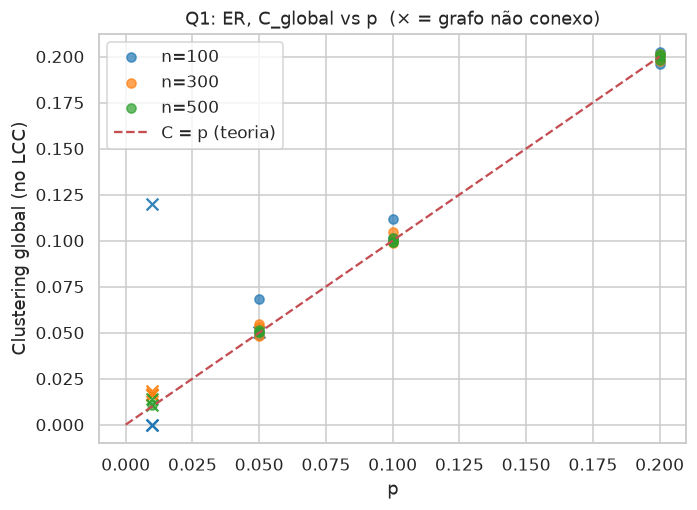

In [5]:
er = df[df.model == "ER"].copy()

piv_c = er.pivot_table(index="p", columns="n", values="clustering_global")
print("Clustering global médio por (p, n):")
print(piv_c.round(4))
print("\nRazão C/p média por (p, n):")
print(piv_c.div(piv_c.index.values, axis=0).round(2))
print("\nFração do LCC (média) por (p, n):")
print(er.pivot_table(index="p", columns="n", values="lcc_frac").round(3))

conexo = er[er.lcc_frac == 1]
r_all = stats.pearsonr(er["p"], er["clustering_global"])[0]
r_conn = stats.pearsonr(conexo["p"], conexo["clustering_global"])[0]
print(f"\nPearson(p, C_global), todos os {len(er)} grafos ER:    {r_all:.4f}")
print(f"Pearson(p, C_global), só os {len(conexo)} grafos conexos:   {r_conn:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4.8))
for n, c in zip(N_VALUES, ["tab:blue", "tab:orange", "tab:green"]):
    sub = er[er.n == n]
    full = sub[sub.lcc_frac == 1]; part = sub[sub.lcc_frac < 1]
    ax.scatter(full["p"], full["clustering_global"], color=c, alpha=0.7, label=f"n={n}")
    ax.scatter(part["p"], part["clustering_global"], color=c, alpha=0.9, marker="x", s=60)
xs = np.linspace(0, er["p"].max(), 50)
ax.plot(xs, xs, "r--", label="C = p (teoria)")
ax.set_xlabel("p"); ax.set_ylabel("Clustering global (no LCC)")
ax.set_title("Q1: ER, C_global vs p  (× = grafo não conexo)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS}/parte1_q1.png", dpi=130, bbox_inches="tight"); plt.show()

**Leitura Q1.** Para p ≥ 0,05 o clustering medido fica muito próximo de p (por exemplo p=0,2: 0,199 a 0,200 nos três n). O desvio visível está em p=0,01: C médio 0,040 (n=100), 0,017 (n=300) e 0,012 (n=500) contra 0,010 teórico, e 8 dos 9 grafos com p=0,01 não são conexos, isto é, o C é medido num LCC pequeno. Isso é um **efeito de seleção do LCC**, e não mera flutuação amostral como a v1.0 afirmava. O Pearson é 0,965 com todos os grafos e 0,998 só com os conexos; como são apenas 4 valores distintos de p, ele é uma medida fraca, e a razão C/p é mais informativa.

## Q2: redes BA são assortativas ou dissortativas?

O agrupamento agora é pelo **m nominal** (1, 2, 5, 10), separado por n. Na v1.0 o eixo mostrava o número de arestas (99, 196, 299, ...), por causa do bug.

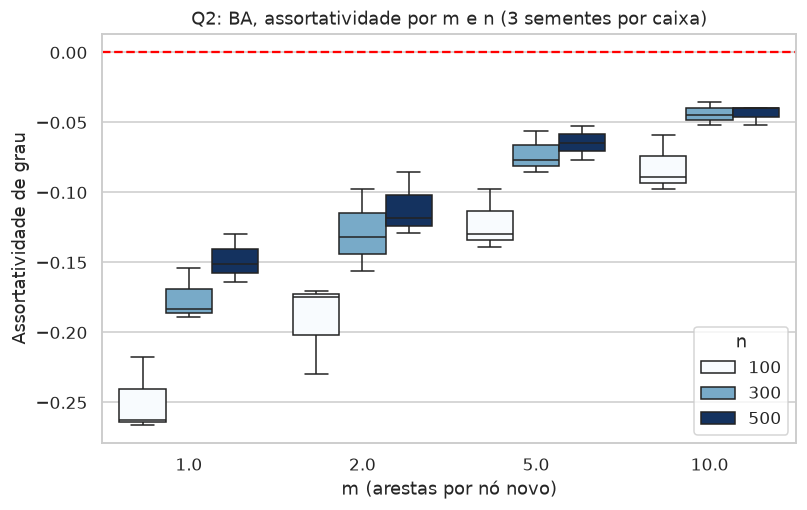

Assortatividade média por m (todos os n e sementes):
        mean     std  count
m                          
1.0  -0.1909  0.0486      9
2.0  -0.1437  0.0443      9
5.0  -0.0864  0.0306      9
10.0 -0.0566  0.0222      9

Assortatividade média por m e n:
n        100     300     500
m                           
1.0  -0.2488 -0.1756 -0.1484
2.0  -0.1914 -0.1286 -0.1110
5.0  -0.1219 -0.0728 -0.0646
10.0 -0.0820 -0.0439 -0.0438

Média geral BA: -0.1194
Assortatividade ER (média): -0.0402


In [6]:
ba = df[df.model == "BA"].copy()

fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.boxplot(data=ba, x="m", y="assortativity", hue="n", palette="Blues", ax=ax)
ax.axhline(0, color="red", ls="--")
ax.set_xlabel("m (arestas por nó novo)"); ax.set_ylabel("Assortatividade de grau")
ax.set_title("Q2: BA, assortatividade por m e n (3 sementes por caixa)")
plt.tight_layout(); plt.savefig(f"{RESULTS}/parte1_q2.png", dpi=130, bbox_inches="tight"); plt.show()

print("Assortatividade média por m (todos os n e sementes):")
print(ba.groupby("m")["assortativity"].agg(["mean", "std", "count"]).round(4))
print("\nAssortatividade média por m e n:")
print(ba.pivot_table(index="m", columns="n", values="assortativity").round(4))
print(f"\nMédia geral BA: {ba['assortativity'].mean():.4f}")
print(f"Assortatividade ER (média): {df[df.model=='ER']['assortativity'].mean():.4f}")

**Leitura Q2.** Todas as redes BA do grid são dissortativas (assortatividade < 0), com média geral −0,119. Porém a magnitude **diminui** com m: −0,191 (m=1), −0,144 (m=2), −0,086 (m=5), −0,057 (m=10). A v1.0 afirmava o contrário ("a dissortatividade aumenta com m"), e isso estava errado (o gráfico entregue já mostrava o efeito certo dentro de cada n, mas o eixo era ilegível). A dissortatividade também diminui com n (para m=1: −0,249, −0,176, −0,148 para n=100, 300, 500), coerente com a convergência lenta a valores próximos de zero para n grande.

## Q3: o regime small-world do WS depende de β ou de k?

C(β)/C(0) e L(β)/L(0) são normalizados **por (n, k)** usando a média do β=0 sobre as sementes, e plotados **separadamente para k=4, 6 e 10** (linhas finas: um n; linha grossa: média sobre n e sementes). A grade só tem β ∈ {0,01; 0,1; 0,5; 1}.

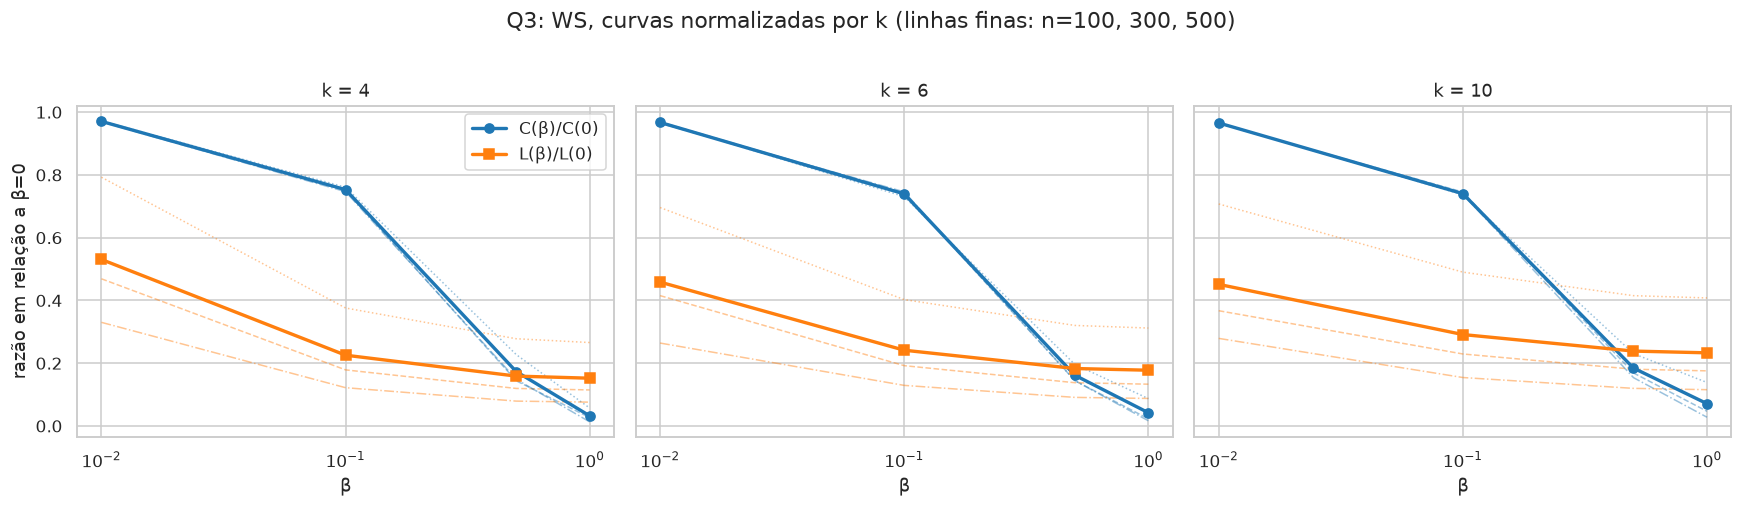

k=4: média sobre n e sementes
beta  0.01   0.10   0.50   1.00
Cn    0.97  0.753  0.173  0.032
Ln    0.53  0.225  0.159  0.152 

k=6: média sobre n e sementes
beta   0.01   0.10   0.50   1.00
Cn    0.967  0.739  0.162  0.042
Ln    0.458  0.241  0.183  0.177 

k=10: média sobre n e sementes
beta   0.01   0.10   0.50   1.00
Cn    0.965  0.740  0.184  0.071
Ln    0.451  0.291  0.238  0.233 

Folga C - L (média sobre n), por k e β:
beta   0.01   0.10   0.50   1.00
k                               
4.0   0.440  0.528  0.015 -0.120
6.0   0.509  0.498 -0.021 -0.135
10.0  0.514  0.449 -0.054 -0.162

L(β)/L(0) por β, k e n (dependência de n):
n            100    300    500
beta k                        
0.01 4.0   0.792  0.469  0.330
     6.0   0.696  0.415  0.264
     10.0  0.707  0.367  0.279
0.10 4.0   0.376  0.179  0.122
     6.0   0.403  0.192  0.129
     10.0  0.490  0.229  0.154
0.50 4.0   0.278  0.119  0.079
     6.0   0.320  0.138  0.091
     10.0  0.415  0.181  0.120
1.00 4.0   0.266  0

In [7]:
ws = df[df.model == "WS"].copy()
base = (ws[ws.beta == 0].groupby(["n", "k"])[["clustering_avg", "avg_shortest_path"]].mean()
          .rename(columns={"clustering_avg": "c0", "avg_shortest_path": "l0"}))
ws = ws.join(base, on=["n", "k"])
ws["Cn"] = ws["clustering_avg"] / ws["c0"]
ws["Ln"] = ws["avg_shortest_path"] / ws["l0"]
wsb = ws[ws.beta > 0]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, k in zip(axes, WS_K):
    sub = wsb[wsb.k == k]
    for n, ls in zip(N_VALUES, [":", "--", "-."]):
        g = sub[sub.n == n].groupby("beta")[["Cn", "Ln"]].mean()
        ax.plot(g.index, g["Cn"], ls, color="tab:blue", alpha=0.45, lw=1)
        ax.plot(g.index, g["Ln"], ls, color="tab:orange", alpha=0.45, lw=1)
    g = sub.groupby("beta")[["Cn", "Ln"]].mean()
    ax.plot(g.index, g["Cn"], "o-", color="tab:blue", lw=2.2, label="C(β)/C(0)")
    ax.plot(g.index, g["Ln"], "s-", color="tab:orange", lw=2.2, label="L(β)/L(0)")
    ax.set_xscale("log"); ax.set_xlabel("β"); ax.set_title(f"k = {k}")
    if k == WS_K[0]: ax.set_ylabel("razão em relação a β=0"); ax.legend()
fig.suptitle("Q3: WS, curvas normalizadas por k (linhas finas: n=100, 300, 500)", y=1.02)
plt.tight_layout(); plt.savefig(f"{RESULTS}/parte1_q3.png", dpi=130, bbox_inches="tight"); plt.show()

for k in WS_K:
    print(f"k={k}: média sobre n e sementes")
    print(wsb[wsb.k == k].groupby("beta")[["Cn", "Ln"]].mean().round(3).T, "\n")
print("Folga C - L (média sobre n), por k e β:")
print(wsb.groupby(["k", "beta"]).apply(lambda x: (x.Cn - x.Ln).mean(), include_groups=False).unstack().round(3))
print("\nL(β)/L(0) por β, k e n (dependência de n):")
print(wsb.pivot_table(index=["beta", "k"], columns="n", values="Ln").round(3))
ws_mean = wsb.groupby("beta")[["Cn", "Ln"]].mean()
print(f"\nMédia sobre k e n em β=0,1:  C/C0 = {ws_mean.loc[0.1,'Cn']:.3f},  L/L0 = {ws_mean.loc[0.1,'Ln']:.3f}")

**Leitura Q3 (somente o que os dados mostram).**

- Em β=0,01 e β=0,1, para os três k testados, C(β)/C(0) continua alto (0,97 e 0,74) enquanto L(β)/L(0) já caiu bastante (0,45 a 0,53 em β=0,01 e 0,23 a 0,29 em β=0,1). A folga C−L é parecida entre k=4, 6 e 10 (0,44 a 0,53). Em β=0,5 e 1 o clustering colapsa e a folga some. Isso é o comportamento clássico de Watts e Strogatz.
- **Não dá para afirmar que a janela é independente de k, nem localizar suas bordas:** a grade tem só dois valores de β (0,01 e 0,1) na região de interesse, e a curva da v1.0 era uma média sobre k e n (que, por construção, não informa nada sobre k).
- A dependência de **n** é mais forte que a de k: em β=0,01, L/L(0) vai de ≈0,70–0,79 (n=100) a ≈0,26–0,33 (n=500). Se há uma "janela", ela se desloca com n.
- Limitações: 3 sementes por ponto, sem intervalo de confiança, β com apenas 4 valores positivos.

## Parte 1: resumo numérico das perguntas

In [8]:
print("Q1 - ER: C/p ~ 1 para p>=0.05; viés de LCC em p=0.01 (ver tabelas acima).")
print(f"Q1 - Pearson(p, C_global): {r_all:.4f} (todos) / {r_conn:.4f} (só grafos conexos)")
print(f"Q2 - Assortatividade média BA: {ba['assortativity'].mean():.4f}  | por m:",
      {int(k): round(v, 3) for k, v in ba.groupby('m')['assortativity'].mean().items()})
print(f"Q3 - Média sobre k e n em beta=0.1: C/C0 = {ws_mean.loc[0.1,'Cn']:.2f}, L/L0 = {ws_mean.loc[0.1,'Ln']:.2f}")

Q1 - ER: C/p ~ 1 para p>=0.05; viés de LCC em p=0.01 (ver tabelas acima).
Q1 - Pearson(p, C_global): 0.9654 (todos) / 0.9978 (só grafos conexos)
Q2 - Assortatividade média BA: -0.1194  | por m: {1: -0.191, 2: -0.144, 5: -0.086, 10: -0.057}
Q3 - Média sobre k e n em beta=0.1: C/C0 = 0.74, L/L0 = 0.25


---
# Parte 2: rede real *ego-Facebook* (SNAP)

**Dados.** `facebook_combined.txt.gz` do SNAP: 10 ego-networks anonimizadas combinadas em um único grafo (4039 nós, 88234 arestas). Citação: J. McAuley e J. Leskovec, *Learning to Discover Social Circles in Ego Networks*, NIPS 2012. Fonte: <https://snap.stanford.edu/data/ego-Facebook.html>. O arquivo é baixado em `../data/` (ignorado pelo git) e **não** é redistribuído aqui.

**Nota sobre amostragem.** O caminho médio e o diâmetro do grafo real e dos paralelos são estimados a partir de 500 fontes escolhidas com `default_rng(42)` (como na v1.0), e a betweenness usa k=500. Mais abaixo, o caminho médio exato do grafo real é calculado para checar o erro da amostragem.

In [9]:
URL = "https://snap.stanford.edu/data/facebook_combined.txt.gz"
FB_PATH = f"{DATA}/facebook_combined.txt.gz"
if not os.path.exists(FB_PATH):
    try:
        urllib.request.urlretrieve(URL, FB_PATH)
    except Exception as e:
        raise RuntimeError(f"Falha ao baixar {URL}: {e}") from e
with gzip.open(FB_PATH, "rt") as f:
    G_real = nx.read_edgelist(f, nodetype=int)
print(f"Facebook real: n={G_real.number_of_nodes()}, m={G_real.number_of_edges()}, "
      f"componentes={nx.number_connected_components(G_real)}")
assert (G_real.number_of_nodes(), G_real.number_of_edges()) == (4039, 88234)

Facebook real: n=4039, m=88234, componentes=1


In [10]:
RNG = np.random.default_rng(42)   # amostragem de fontes (Parte 2); ordem das chamadas fixa => reprodutível

def metrics_large(G, sample=500, bet_k=500):
    if not nx.is_connected(G):
        G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    n, m = G.number_of_nodes(), G.number_of_edges()
    deg = np.array([d for _, d in G.degree()])
    sources = RNG.choice(list(G.nodes()), size=min(sample, n), replace=False)
    lengths = []
    for s in sources:
        d_dict = nx.single_source_shortest_path_length(G, s)
        lengths.extend(v for v in d_dict.values() if v > 0)
    out = {
        "n": n, "m": m,
        "avg_degree": deg.mean(), "max_degree": int(deg.max()),
        "clustering_global": nx.transitivity(G),
        "clustering_avg": nx.average_clustering(G),
        "assortativity": nx.degree_assortativity_coefficient(G),
        "avg_shortest_path": float(np.mean(lengths)),
        "diameter": int(max(lengths)),          # limite inferior (amostra de fontes)
    }
    out["betweenness"] = nx.betweenness_centrality(G, k=min(bet_k, n), seed=0)
    out["degree_c"]    = nx.degree_centrality(G)
    out["closeness"]   = nx.closeness_centrality(G)
    out["pagerank"]    = nx.pagerank(G)
    return out, G

print("Calculando métricas do Facebook real (alguns minutos)...")
real_m, G_real = metrics_large(G_real)

# Paralelos sintéticos com mesmo n e grau médio (uma única semente, 42)
n_r, k_r = real_m["n"], real_m["avg_degree"]
p_eq = 2 * real_m["m"] / (n_r * (n_r - 1))
m_BA = max(1, int(round(k_r / 2)))
k_WS = int(round(k_r)); k_WS = k_WS + 1 if k_WS % 2 else k_WS
print(f"Paralelos: ER(p={p_eq:.4f}), BA(m={m_BA}), WS(k={k_WS}, β=0.1)")
G_er = nx.erdos_renyi_graph(n_r, p_eq, seed=42)
G_ba = nx.barabasi_albert_graph(n_r, m_BA, seed=42)
G_ws = nx.watts_strogatz_graph(n_r, k_WS, 0.1, seed=42)

print("Métricas dos paralelos...")
er_m, _ = metrics_large(G_er)
ba_m, _ = metrics_large(G_ba)
ws_m, _ = metrics_large(G_ws)

def row(name, M):
    return {"modelo": name, "n": M["n"], "m": M["m"],
            "k_medio": round(M["avg_degree"], 2), "max_grau": M["max_degree"],
            "C_global": round(M["clustering_global"], 4), "C_avg": round(M["clustering_avg"], 4),
            "L": round(M["avg_shortest_path"], 3), "diam": M["diameter"],
            "assort": round(M["assortativity"], 4)}
comp = pd.DataFrame([row("Facebook", real_m), row("ER", er_m), row("BA", ba_m), row("WS", ws_m)])
comp.to_csv(f"{RESULTS}/comparacao.csv", index=False)
comp

Calculando métricas do Facebook real (alguns minutos)...


Paralelos: ER(p=0.0108), BA(m=22), WS(k=44, β=0.1)


Métricas dos paralelos...


,modelo,n,m,k_medio,max_grau,C_global,C_avg,L,diam,assort
0,Facebook,4039,88234,43.69,1045,0.5192,0.6055,3.706,8,0.0636
1,ER,4039,87553,43.35,67,0.0108,0.0108,2.611,3,0.0031
2,BA,4039,88374,43.76,522,0.0366,0.0382,2.510,3,-0.0111
3,WS,4039,88858,44.00,51,0.5325,0.5347,2.966,4,0.0042


## Distribuição de grau e índice σ de small-world

σ = (C/C_ER) / (L/L_ER) (Humphries e Gurney, 2008), usando o clustering médio e o caminho médio estimado. Também calculo o caminho médio **exato** do grafo real (todos os pares), para medir o erro da amostragem de 500 fontes.

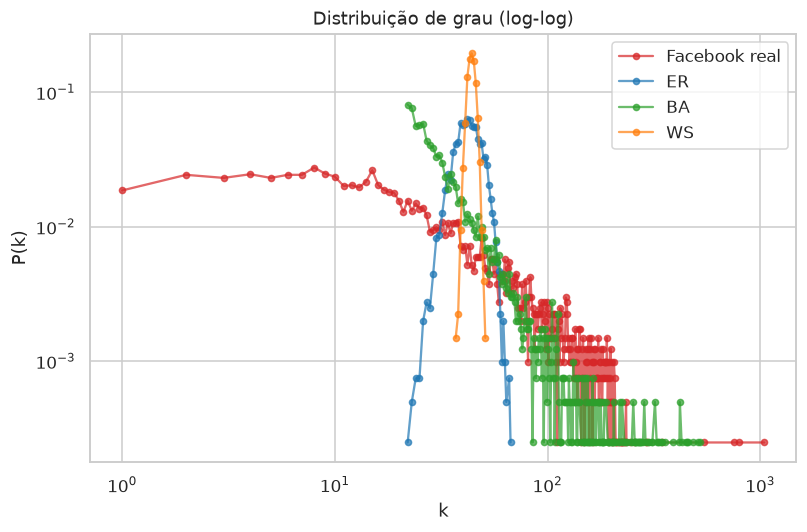

sigma small-world = 39.62   (>>1 => small-world)
C_avg(real)/C_avg(ER)       = 56.24
C_global(real)/C_global(ER) = 48.16
L(real)/L(ER)               = 1.42



L exato (todos os pares) do grafo real: 3.6925  | estimado (500 fontes): 3.7064  | diâmetro exato: 8
Nós com grau > 1000: [107] | nós com grau > 500: 4
Grau do real: mín=1, mediana=25, máx=1045


In [11]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for name, G, c in [("Facebook real", G_real, "tab:red"), ("ER", G_er, "tab:blue"),
                   ("BA", G_ba, "tab:green"), ("WS", G_ws, "tab:orange")]:
    seq = np.array([d for _, d in G.degree()])
    vals, counts = np.unique(seq, return_counts=True)
    mask = vals > 0
    ax.loglog(vals[mask], counts[mask] / counts.sum(), "o-", label=name, color=c, alpha=0.7, ms=4)
ax.set_xlabel("k"); ax.set_ylabel("P(k)")
ax.set_title("Distribuição de grau (log-log)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS}/parte2_distribuicao_grau.png", dpi=130, bbox_inches="tight"); plt.show()

sigma = (real_m["clustering_avg"] / er_m["clustering_avg"]) / (real_m["avg_shortest_path"] / er_m["avg_shortest_path"])
print(f"sigma small-world = {sigma:.2f}   (>>1 => small-world)")
print(f"C_avg(real)/C_avg(ER)       = {real_m['clustering_avg']/er_m['clustering_avg']:.2f}")
print(f"C_global(real)/C_global(ER) = {real_m['clustering_global']/er_m['clustering_global']:.2f}")
print(f"L(real)/L(ER)               = {real_m['avg_shortest_path']/er_m['avg_shortest_path']:.2f}")

tot = cnt = 0
for _, d in nx.all_pairs_shortest_path_length(G_real):
    tot += sum(d.values()); cnt += len(d) - 1
L_exato = tot / cnt
print(f"\nL exato (todos os pares) do grafo real: {L_exato:.4f}  | estimado (500 fontes): {real_m['avg_shortest_path']:.4f}"
      f"  | diâmetro exato: {nx.diameter(G_real)}")
deg_real = dict(G_real.degree())
print("Nós com grau > 1000:", [v for v, d in deg_real.items() if d > 1000], "| nós com grau > 500:", sum(d > 500 for d in deg_real.values()))
print(f"Grau do real: mín={min(deg_real.values())}, mediana={np.median(list(deg_real.values())):.0f}, máx={max(deg_real.values())}")

**Leitura (comparação com os paralelos).**

- **Clustering:** C_avg do real é ≈ **56×** o do ER (C_global ≈ 48×), isto é, dezenas de vezes, e não "centenas" como na v1.0. O WS reproduz bem o clustering (0,53 vs 0,52 global); o BA, não (0,04).
- **Caminho médio:** L do real (3,71) é ≈ **1,42×** o do ER (2,61) e 1,48× o do BA (2,51), então é mais longo que nos paralelos, ainda que curto em termos absolutos (o exato é 3,69). A v1.0 dizia "L do real ≈ L do ER"; essa igualdade é frouxa.
- **σ ≈ 39,6**, e não "tipicamente > 50". Segue muito acima de 1.
- **Grau:** o real tem grau máximo 1045 (ER: 67; BA: 522; WS: 51) e apenas **um** nó com grau > 1000 (a v1.0 dizia "hubs com mais de 1000 conexões"). O mínimo do real é 1 e o do BA é m=22, então o BA não reproduz a parte de baixo da distribuição; a "cauda do BA" não foi quantificada aqui.
- **Assortatividade:** real +0,064 (pequena e positiva), ER +0,003, BA −0,011, WS +0,004.

## Robustez: remoção de nós (passos de 1%, até 40%)

Estratégias:

- **Ataque por grau (estático):** remove nós em ordem decrescente de grau **inicial** (como na v1.0).
- **Ataque por grau (adaptativo):** recalcula o grau a cada remoção.
- **Falhas aleatórias:** média de **30** sequências aleatórias (sementes 1 a 30), com mínimo e máximo; a sequência de semente 0 (usada na v1.0) também é registrada.

A métrica é LCC/n, o tamanho do maior componente dividido pelo n **original** (4039).

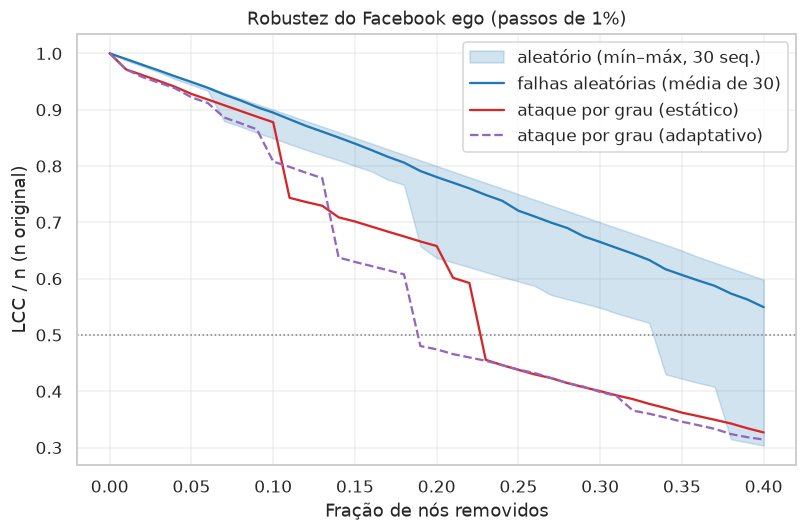

 frac_removida  ataque_estatico  ataque_adaptativo  aleatorio_seed0  aleatorio_media30  aleatorio_min30  aleatorio_max30
          0.05            0.928              0.922            0.950              0.949            0.944            0.950
          0.10            0.878              0.808            0.900              0.895            0.849            0.900
          0.13            0.729              0.778            0.870              0.861            0.819            0.870
          0.20            0.658              0.474            0.791              0.780            0.637            0.800
          0.27            0.423              0.423            0.628              0.699            0.571            0.730
          0.30            0.400              0.399            0.601              0.665            0.548            0.700
          0.40            0.327              0.314            0.511              0.549            0.304            0.598

Primeira fração com LCC/n < 0,5

In [12]:
N0 = G_real.number_of_nodes()
FRACS = [i / 100 for i in range(0, 41)]
CNT = [int(round(f * N0)) for f in FRACS]

def lcc_frac_after(G, removed):
    H = G.subgraph(set(G.nodes()) - set(removed))
    return max((len(c) for c in nx.connected_components(H)), default=0) / N0

deg_order = [v for v, _ in sorted(G_real.degree(), key=lambda x: -x[1])]
static = [lcc_frac_after(G_real, deg_order[:c]) for c in CNT]

H = G_real.copy(); removed = 0; adaptive = []
for c in CNT:
    while removed < c:
        v = max(H.degree(), key=lambda x: x[1])[0]
        H.remove_node(v); removed += 1
    adaptive.append(max((len(x) for x in nx.connected_components(H)), default=0) / N0)

def random_curve(seed):
    order = list(G_real.nodes()); np.random.default_rng(seed).shuffle(order)
    return [lcc_frac_after(G_real, order[:c]) for c in CNT]
rand0 = random_curve(0)
rand_runs = np.array([random_curve(s) for s in range(1, 31)])
rand_mean, rand_min, rand_max = rand_runs.mean(0), rand_runs.min(0), rand_runs.max(0)

rob = pd.DataFrame({"frac_removida": FRACS, "ataque_estatico": static, "ataque_adaptativo": adaptive,
                    "aleatorio_seed0": rand0, "aleatorio_media30": rand_mean,
                    "aleatorio_min30": rand_min, "aleatorio_max30": rand_max})
rob.to_csv(f"{RESULTS}/robustez_fina.csv", index=False)

def first_below(vals, thr):
    for f, x in zip(FRACS, vals):
        if x < thr: return f
    return None
def fmt(f): return f"{100*f:.0f}%" if f is not None else "não ocorre até 40%"

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.fill_between(FRACS, rand_min, rand_max, color="tab:blue", alpha=0.2, label="aleatório (mín–máx, 30 seq.)")
ax.plot(FRACS, rand_mean, "-", color="tab:blue", label="falhas aleatórias (média de 30)")
ax.plot(FRACS, static, "-", color="tab:red", label="ataque por grau (estático)")
ax.plot(FRACS, adaptive, "--", color="tab:purple", label="ataque por grau (adaptativo)")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("Fração de nós removidos"); ax.set_ylabel("LCC / n (n original)")
ax.set_title("Robustez do Facebook ego (passos de 1%)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{RESULTS}/parte2_robustez.png", dpi=130, bbox_inches="tight"); plt.show()

print(rob[rob.frac_removida.isin([0.05, 0.10, 0.13, 0.20, 0.27, 0.30, 0.40])].round(3).to_string(index=False))
print("\nPrimeira fração com LCC/n < 0,5:")
for name, v in [("ataque estático", static), ("ataque adaptativo", adaptive),
                ("aleatório (seed 0)", rand0), ("aleatório (média de 30)", list(rand_mean))]:
    print(f"  {name:26s}: {fmt(first_below(v, 0.5))}")
pior = rand_runs[int(np.argmin(rand_runs[:, -1]))]
print(f"  {'aleatório (pior das 30)':26s}: {fmt(first_below(list(pior), 0.5))}")

**Leitura (robustez), sem exagero.**

- O ataque por grau é pior que a falha aleatória em todas as frações acima de ~1%, mas a queda é **gradual, com degraus**, e não um colapso em ~10%: com 10% dos nós removidos o LCC ainda é ≈ **0,88** (estático) / 0,81 (adaptativo), contra ≈ 0,90 no aleatório. A v1.0 dizia que a rede "se fragmenta drasticamente" nessa fração; isso não se sustenta.
- LCC/n cai abaixo de 50% em **23%** dos nós removidos (ataque estático) e em **19%** (adaptativo). Nas falhas aleatórias isso não ocorre até 40% na média de 30 sequências (0,55 em 40%); a pior das 30 sequências cruza 50% em 34%.
- Os degraus acompanham a remoção dos maiores hubs, que são ego-nodes (ver abaixo). Não há "nó único crítico": remover só os 3 maiores deixa o LCC em ≈ 0,99.
- Limitações: uma única rede, ordem de empate dos graus fixada pela ordem do arquivo, 30 sequências aleatórias.

## Os 3 vértices mais importantes (rank médio de 4 centralidades)

Betweenness com k=500 fontes (aproximada, `seed=0`). O resultado é conferido com os **ego-nodes** do dataset: segundo o pacote original do SNAP (`facebook.tar.gz`), os 10 ego-nodes são os ids 0, 107, 348, 414, 686, 698, 1684, 1912, 3437 e 3980 (um arquivo `<id>.edges` por ego). Esses ids foram conferidos manualmente nesse pacote; o notebook só os usa como constante.

In [13]:
EGOS = [0, 107, 348, 414, 686, 698, 1684, 1912, 3437, 3980]   # ver texto acima

df_c = pd.DataFrame({
    "degree":      pd.Series(real_m["degree_c"]),
    "betweenness": pd.Series(real_m["betweenness"]),
    "closeness":   pd.Series(real_m["closeness"]),
    "pagerank":    pd.Series(real_m["pagerank"]),
})
df_c["rank_medio"] = df_c.rank(ascending=False).mean(axis=1)
top3 = df_c.sort_values("rank_medio").head(3).copy()
top3["ego_node"] = top3.index.isin(EGOS)
top3.round(4).to_csv(f"{RESULTS}/top3_vertices.csv")
print("Top 3 por rank médio:"); print(top3.round(4))

def lcc_after_removing(nodes):
    H = G_real.subgraph(set(G_real.nodes()) - set(nodes))
    comps = list(nx.connected_components(H))
    return max(len(c) for c in comps) / N0, len(comps)
print("\nRemovendo os 3 vértices top:   LCC/n = %.3f, componentes = %d" % lcc_after_removing(top3.index))
print("Removendo os 10 ego-nodes:     LCC/n = %.3f, componentes = %d" % lcc_after_removing(EGOS))
print("Maiores graus (ids):", sorted(deg_real, key=lambda v: -deg_real[v])[:6], "...")

Top 3 por rank médio:
      degree  betweenness  closeness  pagerank  rank_medio  ego_node
107   0.2588       0.4823     0.4597    0.0069        1.25      True
1684  0.1961       0.3507     0.3936    0.0064        3.00      True
1912  0.1870       0.2199     0.3509    0.0039       10.00      True

Removendo os 3 vértices top:   LCC/n = 0.991, componentes = 27
Removendo os 10 ego-nodes:     LCC/n = 0.924, componentes = 91
Maiores graus (ids): [107, 1684, 1912, 3437, 0, 2543] ...


**Leitura.** Os três primeiros (107, 1684, 1912) são ego-nodes, e **por construção** do dataset um ego tem aresta para todos os seus amigos, o que explica o grau muito alto. A "importância" aqui é, em boa parte, um **artefato da coleta** (os egos são os usuários cujos amigos foram coletados), e não uma propriedade da rede de amizade completa do Facebook. A v1.0 dizia que remover um ego "desconecta significativamente a rede"; os números acima mostram que isso não é verdade (remover os 3 maiores deixa o LCC em ≈ 0,99).

## Comunidades, triângulos e lei de potência

- **Modularidade:** algoritmo de Louvain (`networkx.community.louvain_communities`) com três sementes fixas (0, 1, 2); como referência, o mesmo algoritmo no paralelo ER.
- **Triângulos:** `sum(nx.triangles(G).values()) / 3`.
- **Lei de potência:** ajuste por máxima verossimilhança com a biblioteca `powerlaw` (Clauset, Shalizi e Newman, 2009), grau como variável discreta, `xmin` estimado. **Limitações:** o ajuste usa só a cauda (≥ xmin), ER, BA e WS não são ajustados, e um bom ajuste de cauda não prova mecanismo de preferential attachment. Comparo com distribuições alternativas pelo teste de razão de verossimilhança (R < 0 favorece a alternativa).

In [14]:
tri = sum(nx.triangles(G_real).values()) // 3
print(f"Triângulos no grafo real: {tri:,}".replace(",", "."))

for s in (0, 1, 2):
    comms = nx.community.louvain_communities(G_real, seed=s)
    q = nx.community.modularity(G_real, comms)
    print(f"Louvain (seed={s}): {len(comms)} comunidades, modularidade Q = {q:.4f}")
comms_er = nx.community.louvain_communities(G_er, seed=0)
print(f"Referência, paralelo ER (seed=0): {len(comms_er)} comunidades, Q = {nx.community.modularity(G_er, comms_er):.4f}")

import powerlaw
d = np.array([x for x in deg_real.values()])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fit = powerlaw.Fit(d, discrete=True, verbose=False)
    print(f"\nLei de potência (cauda): alpha = {fit.power_law.alpha:.3f} ± {fit.power_law.sigma:.3f}, "
          f"xmin = {fit.power_law.xmin:.0f}, nós na cauda = {(d >= fit.power_law.xmin).sum()} de {len(d)}")
    for alt in ("lognormal", "exponential", "truncated_power_law", "stretched_exponential"):
        R, p = fit.distribution_compare("power_law", alt)
        print(f"  lei de potência vs {alt:22s}: R = {R:8.2f}, p = {p:.4f}")

Triângulos no grafo real: 1.612.010


Louvain (seed=0): 16 comunidades, modularidade Q = 0.8349


Louvain (seed=1): 15 comunidades, modularidade Q = 0.8348


Louvain (seed=2): 16 comunidades, modularidade Q = 0.8341


Referência, paralelo ER (seed=0): 8 comunidades, Q = 0.1360



Lei de potência (cauda): alpha = 2.510 ± 0.043, xmin = 47, nós na cauda = 1250 de 4039
  lei de potência vs lognormal             : R =  -110.42, p = 0.0000
  lei de potência vs exponential           : R =  -109.70, p = 0.0000


  lei de potência vs truncated_power_law   : R =  -109.87, p = 0.0000
  lei de potência vs stretched_exponential : R =  -110.36, p = 0.0000


**Leitura.**

- **Modularidade:** o Louvain encontra 15 a 16 comunidades e modularidade Q = 0,835 (seed 0), 0,835 (seed 1) e 0,834 (seed 2). Esse valor é alto e bem acima do paralelo ER (Q = 0,136, com 8 comunidades), compatível com a presença de comunidades. O número de comunidades depende do algoritmo e da semente e não deve ser lido como "o" número de comunidades.
- **Triângulos:** 1.612.010, que coincide com o valor publicado pelo SNAP.
- **Lei de potência:** o ajuste da cauda (grau ≥ 47, 1250 nós) dá α ≈ 2,51 ± 0,04, dentro da faixa 2–3 que a v1.0 citava. **Mas a lei de potência pura não descreve bem essa cauda:** o teste de razão de verossimilhança a rejeita (R ≈ −110, p ≈ 0) em favor de lognormal, exponencial, lei de potência truncada e exponencial esticada. (Conferi R contra a truncada e a exponencial com um cálculo próprio de máxima verossimilhança, e o resultado se repete: log-verossimilhança −6361,5 para a lei de potência contra −6251,7 e −6251,8.) Conclusão: cauda pesada sim, mas com corte exponencial, o que combina com 'broad-scale' e **não** com 'livre de escala'. Ressalvas: R fica quase igual entre as alternativas porque todas absorvem o mesmo corte; xmin = 47 foi escolhido pelo próprio ajuste; e os maiores graus pertencem a poucos ego-nodes, então a cauda é uma amostra pequena e influenciada pela coleta.

## Discussão qualitativa (sem número novo)

**Difusão de informação.** Estruturalmente favorável: o caminho médio é curto (≈ 3,7 saltos), há hubs de grau alto, e o clustering elevado torna a vizinhança local redundante. Por outro lado, a modularidade alta sugere que a informação pode ficar contida em comunidades. Isso é uma interpretação plausível da estrutura, **não foi simulado nenhum processo de difusão** neste trabalho.

**Preservação de informação.** Vale o mesmo cuidado. Os 1,6 milhão de triângulos indicam muita redundância local (vários caminhos curtos entre vizinhos). A medição de robustez acima mostra que remover nós por grau reduz o LCC de forma gradual, não abrupta. Afirmações sobre "pontes inter-comunitárias críticas" não foram testadas aqui (não calculamos betweenness de arestas nem a remoção de arestas).

**Navegabilidade (discussão teórica, sem experimento).** No sentido de Kleinberg (2000), uma rede é navegável quando um agente com informação apenas local (vizinhos e uma noção de "distância" ao alvo) encontra caminhos curtos com roteamento guloso. Isso depende de como as ligações de longo alcance se distribuem em relação a uma estrutura subjacente (no modelo de Kleinberg, probabilidade ∝ d⁻ʳ, e só r = dimensão do espaço dá navegabilidade eficiente). Redes com caminho médio curto e clustering alto, como esta, *podem* ser navegáveis, mas caminho curto não implica navegabilidade: é preciso uma noção de proximidade que guie a busca, e **este trabalho não a mede nem simula roteamento guloso**. Os resultados clássicos de Milgram (1967) e estudos posteriores são evidência empírica sobre redes sociais humanas em geral, não sobre este grafo.

**Síntese.** Esta rede é small-world (C alto, L curto, σ ≈ 40) com distribuição de grau de cauda pesada, não é de escala livre estrita e não é nem aleatória (ER) nem bem descrita por um único modelo nulo: o WS captura clustering e caminho, o BA captura parte da heterogeneidade de grau, e nenhum captura os dois.

## Limitações do estudo

- **Uma única rede real**, coletada em 2012 de um subconjunto de usuários (10 ego-networks): generalizar para "redes sociais" ou para o Facebook de hoje não é justificado.
- **Parte 1:** 3 sementes por configuração, sem intervalos de confiança; grade pequena (n ≤ 500; β com 4 valores positivos).
- **Parte 2:** paralelos sintéticos com uma única semente; caminho médio, diâmetro e betweenness estimados por amostra de fontes (o L exato foi checado: erro ≈ 0,4%).
- A importância de vértices e parte da estrutura de hubs refletem o **procedimento de coleta** (egos ligados a todos os seus amigos).